Graph Preparation

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import os
from torch_geometric.datasets import EllipticBitcoinDataset
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import to_undirected
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    f1_score, precision_score, recall_score
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# Download the dataset if it is not already available in this session
dataset = EllipticBitcoinDataset(root="/content/elliptic")
data = dataset[0]

# Get the raw file path from PyG instead of hardcoding it
feat_path = os.path.join(dataset.raw_dir, "elliptic_txs_features.csv")
print("file:", feat_path, "| exists:", os.path.exists(feat_path))

# Load timestamps (PyG does not include them; the node order is unchanged)
ts = pd.read_csv(feat_path, header=None, usecols=[1])[1].values
ts = torch.tensor(ts)
print("time steps:", ts.min().item(), "-", ts.max().item(),
      "| nodes:", len(ts))

d = data.clone()
d.edge_index = to_undirected(d.edge_index)  # Make edges bidirectional
d = d.to(device)
ts = ts.to(device)

train_full = d.train_mask          # Labeled nodes from time steps 1-34
test_m = d.test_mask               # Labeled nodes from time steps 35-49
sub_train = train_full & (ts <= 29)  # Training subset for Phase A
val_m = train_full & (ts >= 30)    # Validation subset

print("train_full:", train_full.sum().item(),
      "| sub_train:", sub_train.sum().item(),
      "| val:", val_m.sum().item(),
      "| test:", test_m.sum().item())

# Verify that the timestamps match the PyG masks
print("train: time steps", ts[train_full].min().item(),
      "-", ts[train_full].max().item())
print("test:  time steps", ts[test_m].min().item(),
      "-", ts[test_m].max().item())

device: cuda


Processing...
Done!


file: /content/elliptic/raw/elliptic_txs_features.csv | exists: True
time steps: 1 - 49 | nodes: 203769
train_full: 29894 | sub_train: 26381 | val: 3513 | test: 16670
train: time steps 1 - 34
test:  time steps 35 - 49


GraphSAGE Model

In [4]:
class SAGE(nn.Module):
    def __init__(self, in_dim, hidden=128, out_dim=2, dropout=0.3):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden)  # Layer 1: node features and neighbor aggregation
        self.conv2 = SAGEConv(hidden, out_dim)  # Layer 2: produce two class scores
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)

Training and Evaluation

In [5]:
@torch.no_grad()
def evaluate(model, mask):
    model.eval()
    out = model(d.x, d.edge_index)

    proba = out.softmax(dim=-1)[:, 1][mask].cpu().numpy()  # Probability of illicit activity
    y_true = d.y[mask].cpu().numpy()
    pred = (proba >= 0.5).astype(int)

    return {
        "pr_auc": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
        "f1_illicit": f1_score(y_true, pred),
        "f1_macro": f1_score(y_true, pred, average="macro"),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
    }


def train_model(seed, train_mask, epochs, val_mask=None):
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = SAGE(d.num_features).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.005,
        weight_decay=5e-4
    )

    y_tr = d.y[train_mask]

    # Assign a higher weight to the minority class, similar to scale_pos_weight in XGBoost
    w = torch.tensor(
        [
            1.0,
            (y_tr == 0).sum().item() / (y_tr == 1).sum().item()
        ],
        device=device
    )

    val_curve = []

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()

        out = model(d.x, d.edge_index)  # Run message passing over the entire graph

        # Calculate loss only on labeled training nodes
        loss = F.cross_entropy(out[train_mask], y_tr, weight=w)

        loss.backward()
        optimizer.step()

        if val_mask is not None:
            val_curve.append(evaluate(model, val_mask)["pr_auc"])

    return model, val_curve

Phase A — Select the Number of Epochs and Plot the Validation Curve

Best epoch: 188, validation PR-AUC = 0.945


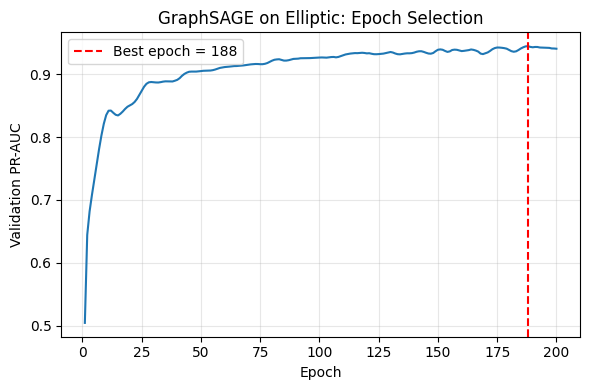

In [6]:
import os
import matplotlib.pyplot as plt

_, curve = train_model(
    seed=0,
    train_mask=sub_train,
    epochs=200,
    val_mask=val_m
)

best_epoch = int(np.argmax(curve)) + 1

print(f"Best epoch: {best_epoch}, validation PR-AUC = {max(curve):.3f}")

os.makedirs("results/figures", exist_ok=True)

plt.figure(figsize=(6, 4))
plt.plot(range(1, 201), curve)
plt.axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Validation PR-AUC")
plt.title("GraphSAGE on Elliptic: Epoch Selection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/figures/elliptic_sage_val_curve.png", dpi=200)
plt.show()

Phase B — Train with 5 Seeds and Evaluate on the Test Set

In [7]:
rows = []

for seed in range(5):
    model, _ = train_model(
        seed,
        train_mask=train_full,
        epochs=best_epoch
    )

    res = evaluate(model, test_m)

    res.update({
        "model": f"GraphSAGE (2 layers, {best_epoch} epochs)",
        "seed": seed
    })

    rows.append(res)

results_sage = pd.DataFrame(rows)

metrics = [
    "pr_auc",
    "roc_auc",
    "f1_illicit",
    "f1_macro",
    "precision",
    "recall"
]

summary_sage = (
    results_sage
    .groupby("model")[metrics]
    .agg(["mean", "std"])
    .round(3)
)

summary_sage

pr_auc        roc_auc        f1_illicit  \
                                   mean    std    mean    std       mean   
model                                                                      
GraphSAGE (2 layers, 188 epochs)  0.684  0.028     0.9  0.003      0.666   

                                        f1_macro        precision         \
                                    std     mean    std      mean    std   
model                                                                      
GraphSAGE (2 layers, 188 epochs)  0.024    0.822  0.013     0.697  0.053   

                                 recall         
                                   mean    std  
model                                           
GraphSAGE (2 layers, 188 epochs)  0.639  0.006

Save the Results

In [8]:
results_sage.to_csv("results/elliptic_graphsage.csv", index=False)
summary_sage.to_csv("results/elliptic_graphsage_summary.csv")